# Лабораторна робота № 5
## Географічні дані OpenStreetMap: від тегів до маршруту

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви - аналітик у туристичному застосунку. Завдання: для заданого міста
**відібрати десять найвартісніших історико-культурних об'єктів** і
**спланувати піший маршрут**, який починається на залізничному вокзалі,
обходить усі десять і повертається на вокзал.

Слово «найвартісніші» в даних не записане. Критерій ви побудуєте самі -
і захистите його.

Потім те саме для **тридцяти** об'єктів. Результат цієї, більшої задачі
стане базою порівняння в **лабораторній роботі № 8**, де ту саму задачу
розв'язуватимуть генетичним та мурашиним алгоритмами.

### Що здаєте

1. Цей ноутбук із виконаними комірками (усі виводи збережені).
2. Файл `lr5_результати.json` - результати для ЛР8.
3. Карту `lr5_маршрут.html`.
4. Звіт у кінці ноутбука: відповіді на сім питань.

### Що оцінюється

| критерій | 0 | 2 | 3 | 4 |
|---|---|---|---|---|
| Відбір об'єктів | теги взято навмання | фільтр працює | фільтр обґрунтовано | показано, що відкинуто і чому |
| Критерій рейтингу | немає | є формула | ваги пояснено | порівняно з альтернативним критерієм |
| Маршрут | не будується | будується | перевірено коректність | пояснено різницю методів числом |
| Карта | немає | точки на карті | маршрут по ребрах графа | видно різницю з прямими відрізками |
| Звіт | немає | формально | з числами | з висновком, якого не було в завданні |

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Місто підтягнеться само.

In [1]:
STUDENT_NAME = 'Стик Назарій Олегович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 17      # номер у списку групи

CITIES = [
    'Львів', 'Київ', 'Харків', 'Одеса', 'Дніпро',
    'Чернівці', 'Івано-Франківськ', 'Тернопіль', 'Ужгород', 'Луцьк',
    'Рівне', 'Хмельницький', 'Вінниця', 'Житомир', 'Чернігів',
    'Черкаси', 'Полтава', 'Суми', 'Кропивницький', 'Запоріжжя',
    'Миколаїв', 'Кривий Ріг', 'Кам\u2019янець-Подільський', 'Мукачево',
    'Коломия', 'Дрогобич', 'Біла Церква', 'Ніжин', 'Остріг', 'Умань',
]

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
CITY = CITIES[(LIST_NUMBER - 1) % len(CITIES)] + ', Україна'
print('варіант %d: %s' % (LIST_NUMBER, CITY))

варіант 17: Полтава, Україна


> Якщо викладач призначив вам інше місто - просто перепишіть `CITY` вручну
> і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['osmnx', 'geopandas', 'shapely', 'pyproj', 'pyarrow',
            'folium', 'mapclassify', 'h3', 'networkx']
missing = [p for p in REQUIRED if importlib.util.find_spec(p) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import json, time, os, collections
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import folium
from xyzservices import providers as xyz

BASEMAP = xyz.Esri.WorldGrayCanvas   # CARTO з 2026 р. вимагає ключ API
pd.set_option('display.width', 200)
print('geopandas', gpd.__version__)

geopandas 1.2.0


---
## 1. Два способи дістати дані

Робоча програма вимагає порівняти два способи доступу **за обсягом переданих
даних і за часом**:

* **живий запит** - `osmnx` питає Overpass API просто зараз;
* **знімок** - ті самі дані, збережені у файли GeoParquet, читаються з диска.

Нижче - живий запит. Запустіть його **один раз**: він збереже теку зі знімком,
і всі наступні запуски читатимуть з неї.

> Overpass - безкоштовний сервіс і обмежує частоту. Якщо запит не пройшов -
> зачекайте хвилину й повторіть. Якщо не проходить взагалі, візьміть
> резервний знімок у викладача і вкажіть це у звіті.

In [4]:
import osmnx as ox

OUT = 'osm_' + CITY.split(',')[0].strip().lower().replace(' ', '_')
os.makedirs(OUT, exist_ok=True)
ox.settings.use_cache = True
ox.settings.cache_folder = os.path.join(OUT, 'cache')
ox.settings.requests_timeout = 300
ox.settings.overpass_rate_limit = True

TOURISM_OK = ['museum', 'attraction', 'gallery', 'artwork', 'viewpoint']

def cache_bytes():
    import pathlib
    p = pathlib.Path(ox.settings.cache_folder)
    return sum(f.stat().st_size for f in p.glob('*.json')) if p.exists() else 0

print('тека знімка:', OUT)

тека знімка: osm_полтава


### Дві налаштовані дрібниці, без яких запит не пройде

Це не формальності - кожна з них ламає збір по-своєму, і жодна не схожа
на свою справжню причину.

**Представитись.** Overpass відповідає **HTTP 406** клієнтові, який прийшов
із типовим заголовком `python-requests`. `osmnx` надсилає свій `User-Agent`
сам, але якщо ви звертаєтесь до сервісу напряму - надсилайте теж.
Рядок має бути **лише латиницею**: HTTP-заголовки передаються в latin-1,
і кирилиця кладе запит помилкою `UnicodeEncodeError` ще до відправлення.

**Обрати машину.** За іменем `overpass-api.de` стоїть кілька серверів, і
частина з них відмовляє у з’єднанні. `osmnx` закріплює одну адресу на
всю сесію - навмисно, щоб не порушувати облік слотів. Якщо закріпиться та,
що відмовляє, впаде весь збір. Тому адресу обираємо самі, вже перевірену.

In [ ]:
import socket

USER_AGENT = ('LvivPolytechnic-SK26-coursework/1.0 '
              '(https://lpnu.ua; student lab assignment)')
assert USER_AGENT.isascii(), 'HTTP-заголовки - latin-1, кирилиця тут не працює'
ox.settings.http_user_agent = USER_AGENT


def pin_working_ip(hostname, port=443, timeout=8):
    """Закріпити для цього імені адресу, яка справді відповідає."""
    try:
        infos = socket.getaddrinfo(hostname, port, socket.AF_INET, socket.SOCK_STREAM)
    except Exception as e:
        print('не вдалось резолвити %s: %s' % (hostname, type(e).__name__))
        return None
    ips = sorted({i[4][0] for i in infos})
    good = []
    for ip in ips:
        s = socket.socket(); s.settimeout(timeout)
        try:
            s.connect((ip, port)); good.append(ip)
        except Exception:
            pass
        finally:
            s.close()
    print('%s: машин %d, відповідають %d %s' % (hostname, len(ips), len(good), good))
    if not good:
        return None
    original = socket.gethostbyname
    socket.gethostbyname = lambda h: good[0] if h == hostname else original(h)
    print('закріплено', good[0])
    return good[0]


pin_working_ip('overpass-api.de')

overpass-api.de: машин 2, відповідають 1 ['65.109.112.52']
закріплено 65.109.112.52


'65.109.112.52'

> Якщо жодна машина не відповіла - виконайте комірку ще раз за хвилину,
> або візьміть у викладача резервний знімок і зазначте це у звіті.
> Інші дзеркала перелічені на сторінці
> [Overpass API](https://wiki.openstreetmap.org/wiki/Overpass_API);
> адресу можна підставити у `ox.settings.overpass_url`.

### Завдання 1.1

Допишіть функцію `fetch`: вона має зберегти шар у `.parquet`, а якщо файл
уже є - прочитати його, **не звертаючись до мережі**. Поверніть також,
скільки МБ пішло мережею і скільки секунд це зайняло.

Підказка щодо `clean`: у OSM одна колонка може містити і число, і список
(ребро, склеєне з кількох шляхів). Parquet вимагає один тип на колонку,
тому неоднорідну колонку треба звести до тексту **цілком**.

In [ ]:
def clean(gdf):
    g = gdf.reset_index()
    for c in g.columns:
        if c == 'geometry':
            continue
        boxed = g[c].map(lambda v: isinstance(v, (list, dict, set, tuple))).any()
        if boxed or g[c].dtype == object:
            g[c] = g[c].map(
                lambda v: None if v is None or (isinstance(v, float) and pd.isna(v))
                else (json.dumps(v, ensure_ascii=False)
                      if isinstance(v, (list, dict, set, tuple)) else str(v))
            ).astype('string')
    return g


COST = {}

def fetch(name, getter):
    """Повертає шар. Якщо файл уже збережено - читає з диска."""
    path = os.path.join(OUT, name + '.parquet')
    if os.path.exists(path) and os.path.getsize(path) > 0:
        t0 = time.time()
        g = gpd.read_parquet(path)
        COST[name] = {'спосіб': 'знімок', 'записів': len(g),
                      'передано_МБ': 0.0,
                      'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                      'секунд': round(time.time() - t0, 3)}
        return g

    # ----- ВАШ КОД: живий запит -----
    # 1) запам'ятовуємо час і розмір кешу ДО запиту
    t0, b0 = time.time(), cache_bytes()
    # 2) робимо запит, чистимо і зберігаємо на диск
    g = clean(getter())
    g.to_parquet(path, index=False)
    g = gpd.read_parquet(path)   # читаємо назад, щоб типи колонок були такі самі, як у знімку
    # 3) записуємо, скільки це коштувало
    COST[name] = {'спосіб': 'живий запит', 'записів': len(g),
                  'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                  'файл_МБ': round(os.path.getsize(path) / 1e6, 3),
                  'секунд': round(time.time() - t0, 1)}
    return g

In [7]:
boundary = fetch('boundary', lambda: ox.geocode_to_gdf(CITY))
poly = boundary.geometry.iloc[0]
print('межа міста отримана, площа %.1f км²'
      % (boundary.to_crs(32635).area.iloc[0] / 1e6))

межа міста отримана, площа 106.0 км²


In [8]:
heritage = fetch('heritage', lambda: ox.features_from_polygon(
    poly, {'historic': True, 'tourism': TOURISM_OK}))
stations = fetch('stations', lambda: ox.features_from_polygon(
    poly, {'railway': ['station', 'halt'], 'building': ['train_station']}))
amenities = fetch('amenities', lambda: ox.features_from_polygon(
    poly, {'amenity': ['cafe', 'restaurant', 'drinking_water', 'toilets']}))

# Мережа приходить двома таблицями одразу, тому їй окрема гілка.
NODES_P = os.path.join(OUT, 'road_nodes.parquet')
EDGES_P = os.path.join(OUT, 'road_edges.parquet')

if os.path.exists(NODES_P) and os.path.exists(EDGES_P):
    t0 = time.time()
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'знімок', 'записів': len(nodes) + len(edges),
                           'передано_МБ': 0.0,
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 3)}
else:
    t0, b0 = time.time(), cache_bytes()
    G_raw = ox.graph_from_polygon(poly, network_type='walk')
    nodes, edges = ox.convert.graph_to_gdfs(G_raw)
    clean(nodes).to_parquet(NODES_P, index=False)
    clean(edges).to_parquet(EDGES_P, index=False)
    nodes, edges = gpd.read_parquet(NODES_P), gpd.read_parquet(EDGES_P)
    COST['мережа walk'] = {'спосіб': 'живий запит', 'записів': len(nodes) + len(edges),
                           'передано_МБ': round((cache_bytes() - b0) / 1e6, 3),
                           'файл_МБ': round((os.path.getsize(NODES_P)
                                             + os.path.getsize(EDGES_P)) / 1e6, 3),
                           'секунд': round(time.time() - t0, 1)}

print('вузлів %d | ребер %d' % (len(nodes), len(edges)))

вузлів 18066 | ребер 50680


### Завдання 1.2

Зведіть `COST` у таблицю і дайте відповідь у звіті: **у скільки разів
читання знімка швидше за живий запит** і **скільки мегабайтів ви не передали
мережею** при повторному запуску.

Контрольна ознака правильності: при **другому** запуску ноутбука всі рядки
мають мати спосіб «знімок», а `передано_МБ` - нуль.

In [9]:
display(pd.DataFrame(COST).T)

,спосіб,записів,передано_МБ,файл_МБ,секунд
boundary,знімок,1,0.0,0.024,0.058
heritage,знімок,183,0.0,0.08,0.026
stations,знімок,20,0.0,0.036,0.018
amenities,знімок,325,0.0,0.082,0.02
мережа walk,знімок,68746,0.0,3.445,0.059


**Перший запуск (живий запит), 09.11.2026**

| шар | спосіб | записів | передано, МБ | файл, МБ | секунд |
|---|---|---|---|---|---|
| boundary | живий запит | 1 | 0.014 | 0.024 | 1.3 |
| heritage | живий запит* | 183 | 0.141* | 0.080 | ≈79* |
| stations | живий запит* | 20 | 0.023* | 0.036 | ≈100* |
| amenities | живий запит | 325 | 0.121 | 0.082 | 103.4 |
| мережа walk | живий запит | 68746 | 8.400 | 3.445 | 110.2 |
| **разом** | | | **8.70** | **3.67** | **≈394** |

\* Overpass повертав 502 (сервер перевантажений), комірку довелось перезапускати,
і для heritage та stations виміри в `COST` перезаписались. Обсяг узято з розміру
файлів кешу osmnx, час - з часових міток файлів.

**Висновок (завдання 1.2).** Повторний запуск читає всі 5 шарів зі знімка за 0,18 с
проти ≈394 с живого запиту - у ≈2 200 разів швидше. Мережею при цьому не передано
8,70 МБ. На диску знімок займає лише 3,67 МБ: parquet стискає дані й зберігає їх
по колонках, тому він у ≈2,4 раза менший за сирий JSON від сервера.

Майже весь час живого запиту - це не завантаження, а очікування черги на сервері
Overpass (обмеження частоти, а під час роботи ще й помилки 502 «сервер перевантажений»).
Навіть межа міста (один полігон, 14 КБ) з мережі йде в 22 рази довше, ніж з диска.
Знімок, крім швидкості, дає відтворюваність: дані не змінюються між запусками,
і робота не залежить від того, чи живий сервер.

> **Чому пішохідна мережа, а не автомобільна.** У старому місті музеї стоять
> за сотню метрів один від одного, а автомобільних вузлів там одиниці. Кілька
> пам'яток сядуть на **один** вузол графа, і матриця віддалей скаже, що між
> ними нуль метрів. Задача розв'яжеться, відповідь буде неправильною, і
> повідомлення про помилку не з'явиться. У кроці 4 ви це перевірите явно.

---
## 2. Хто претендує на звання пам'ятки

У OpenStreetMap немає тега «визначна пам'ятка». Є два сімейства:

* `historic=*` - `castle`, `church`, `monument`, `memorial`, `ruins`, `tower`, `yes`…
* `tourism=*` - `museum`, `gallery`, `attraction`, `artwork`, `viewpoint`

Перетин неповний: музей у сучасній будівлі має лише `tourism`, руїни фортеці -
лише `historic`. Тому беремо **об'єднання**.

📖 <https://wiki.openstreetmap.org/wiki/Map_Features>

### Завдання 2.1

Відберіть кандидатів і **назвіть у звіті, скільки об'єктів ви відкинули й чому**.

In [10]:
# ----- ВАШ КОД -----
# 2.1 Відбір кандидатів
is_hist  = heritage['historic'].notna() # має будь-який historic=*
is_tour  = heritage['tourism'].isin(TOURISM_OK) # tourism з нашого переліку
has_name = heritage['name'].notna() # має назву

mask = is_hist | is_tour # об'єднання двох умов («або»)
cand = heritage[mask & has_name].reset_index(drop=True)

print('усього у шарі heritage :', len(heritage))
print('  historic заповнений  :', int(is_hist.sum()))
print('  tourism з переліку   :', int(is_tour.sum()))
print('  і те, і те           :', int((is_hist & is_tour).sum()))
print('підходять за тегами    :', int(mask.sum()))
print('з них мають name       :', len(cand))
print('відкинуто              :', len(heritage) - len(cand))

# що саме відкинули - по типах
dropped = heritage[~(mask & has_name)]
print()
print('відкинуті (historic / tourism):')
print(dropped[['historic', 'tourism']].fillna('—').value_counts().to_string())

усього у шарі heritage : 183
  historic заповнений  : 135
  tourism з переліку   : 52
  і те, і те           : 4
підходять за тегами    : 183
з них мають name       : 151
відкинуто              : 32

відкинуті (historic / tourism):
historic       tourism  
—              viewpoint    15
memorial       —            13
wayside_cross  —             1
monument       —             1
—              artwork       1
ruins          —             1


In [11]:
assert 'cand' in dir(), 'спершу виконайте завдання 2.1'
print('=== historic ===');  print(cand['historic'].value_counts().head(10).to_string())
print()
print('=== tourism ===');   print(cand['tourism'].value_counts().head(10).to_string())
print()
print('типи геометрії:', cand.geometry.geom_type.value_counts().to_dict())

=== historic ===
historic
memorial         64
aircraft         21
cannon           17
vehicle           6
monument          4
tank              2
wayside_cross     1
locomotive        1
missile           1
building          1

=== tourism ===
tourism
museum        16
artwork       11
attraction     8
viewpoint      1
yes            1

типи геометрії: {'Point': 128, 'Polygon': 21, 'LineString': 2}


> **Перевірте себе.** Серед типів геометрії мають бути і `Point`, і `Polygon`.
> Якщо самі лише полігони - ви відфільтрували зайве: пам'ятники, меморіали та
> оглядові точки в OSM є **вузлами**, у них немає будівлі.

### Якщо кандидатів менше тридцяти

Невелике місто може дати 15–20 об'єктів. Тоді:

1. розширте перелік `tourism` (наприклад, додайте `theatre`, `place_of_worship`);
2. або зменште `N_LARGE` до того, що є;

і **обов'язково зазначте це у звіті** разом із числом.

---
## 3. Критерій «найкращі»

Ключовий крок роботи. Стовпця «цінність» у даних немає. Його треба
сконструювати і захистити.

Сигнали, які є в OSM:

| сигнал | що означає |
|---|---|
| `wikidata` / `wikipedia` | про об'єкт є стаття - хтось сторонній визнав його вартим опису |
| кількість колонок `name:*` | назву переклали N мовами - перекладають те, що шукають іноземці |
| `tourism=museum/gallery` | призначений для відвідування |
| `historic` заповнений | має історичну природу |
| площа полігона | розмір - **найслабший сигнал**: великим буває і склад |

### Завдання 3.1

Побудуйте числовий рейтинг. Вимоги:

* використати **щонайменше три** різні сигнали;
* звести різнорідні величини до спільної шкали (підказка: `rank(pct=True)`);
* **пояснити у звіті, чому саме такі ваги**.

In [14]:
metric = cand.to_crs(32635)
cand['area_m2'] = np.where(metric.geometry.geom_type.isin(['Polygon', 'MultiPolygon']),
                           metric.area.values, 0.0)

# 3.1 Рейтинг
# сигнал 1: є стаття у Вікіпедії / Вікіданих (0 або 1)
cand['wiki'] = (cand['wikidata'].notna() | cand['wikipedia'].notna()).astype(int)

# сигнал 2: скількома мовами перекладено назву (колонки name:uk, name:en, ...)
lang_cols = [c for c in cand.columns if c.startswith('name:')]
cand['n_lang'] = cand[lang_cols].notna().sum(axis=1)

# сигнал 3: призначений для відвідування - музей або галерея (0 або 1)
cand['museum'] = cand['tourism'].isin(['museum', 'gallery']).astype(int)

# сигнал 4: площа - найслабший, тому найменша вага
cand['score'] = (0.4 * cand['wiki']
               + 0.3 * cand['n_lang'].rank(pct=True)
               + 0.2 * cand['museum']
               + 0.1 * cand['area_m2'].rank(pct=True)).round(3)

print('кандидатів   :', len(cand))
print('мають wiki   :', int(cand['wiki'].sum()))
print('мов у назві  :', cand['n_lang'].value_counts().sort_index().to_dict())
print('музеїв       :', int(cand['museum'].sum()))
print()
print(cand.nlargest(15, 'score')[['name', 'wiki', 'n_lang', 'museum', 'area_m2', 'score']].to_string())

кандидатів   : 151
мають wiki   : 35
мов у назві  : {0: 14, 1: 99, 2: 30, 3: 5, 4: 2, 6: 1}
музеїв       : 16

                                                                    name  wiki  n_lang  museum       area_m2  score
141                                                   Музей В. Короленка     1       4       1  5.975894e+03  0.996
132                                    Музей-садиба І. П. Котляревського     1       3       1  2.792111e+03  0.987
144              Полтавський краєзнавчий музей імені Василя Кричевського     1       3       1  2.479245e+03  0.987
129                   Літературно-меморіальний музей І.П. Котляревського     1       3       1  9.389599e+02  0.985
140                                        Музей авіації та космонавтики     1       3       1  2.691235e+02  0.981
139                                          Садиба-музей Панаса Мирного     1       2       1  1.590905e+04  0.955
135  Полтавський художній музей (галерея мистецтв) імені Миколи Ярошенка     

**Завдання 3.1 - критерій рейтингу**

Сигнали (усі взяті з тегів OSM):

| сигнал | як рахується | вага | чому така вага |
|---|---|---|---|
| wiki | є `wikidata` або `wikipedia` - 1, інакше 0 | 0.4 | найсильніший сигнал: про об'єкт написали статтю сторонні люди, а не лише той, хто малював карту |
| n_lang | скільки колонок `name:*` заповнено (ранг 0..1) | 0.3 | теж зовнішнє визнання (назву перекладають для іноземців), але слабше: частину перекладів додають автоматично |
| museum | `tourism` = museum або gallery - 1, інакше 0 | 0.2 | туристичний застосунок веде туди, куди можна зайти, а не лише подивитись збоку |
| area_m2 | площа полігона (ранг 0..1) | 0.1 | найслабший сигнал: великим буває і склад, а в точкових об'єктів площа 0 |

`score = 0.4*wiki + 0.3*rank(n_lang) + 0.2*museum + 0.1*rank(area_m2)`, максимум 1.

Сигнали мають різні шкали: wiki та museum 0 або 1, n_lang від 0 до 6, а площа від 0 до
1 283 238 м² (поле Полтавської битви). Якщо додати їх напряму, площа перекрила б усе інше.
Тому n_lang і площу переведено в ранги `rank(pct=True)`: кожне значення замінено часткою
об'єктів, які воно перевищує (від 0 до 1). Так поле битви стає просто "першим за площею",
а не "в мільйон разів більшим". Wiki і museum вже мають шкалу 0..1, ранг для них не потрібен.

### Завдання 3.2 - обов'язкове порівняння

Побудуйте **другий** рейтинг за найпростішим критерієм - площею будівлі -
і порахуйте, скільки об'єктів збігається в перших десяти.

Це головне питання роботи: обидва списки отримані з тих самих даних, тим
самим кодом, без жодної помилки. Якщо вони різні - поясніть у звіті, що це
означає для слова «найкращі».

In [16]:
N_SMALL, N_LARGE = 10, 30

# 3.2 Порівняння двох рейтингів
top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)   # 30 кращих за score
top10     = top_score.head(N_SMALL)                                  # перші 10 з них
top_naive = cand.nlargest(N_SMALL, 'area_m2').reset_index(drop=True) # 10 найбільших за площею

overlap = len(set(top10['name']) & set(top_naive['name']))           # скільки назв спільні
print('перетин: %d з %d' % (overlap, N_SMALL))
display(pd.DataFrame({'за моїм критерієм': list(top10['name']),
                      'за площею': list(top_naive['name']),
                      'площа, м²': top_naive['area_m2'].round().astype(int)}))

перетин: 7 з 10


,за моїм критерієм,за площею,"площа, м²"
0,Музей В. Короленка,Полтавська битва,1283238
1,Музей-садиба І. П. Котляревського,Садиба-музей Панаса Мирного,15909
2,Полтавський краєзнавчий музей імені Василя Кри...,Музей В. Короленка,5976
3,Літературно-меморіальний музей І.П. Котляревсь...,Кадетський корпус,4909
4,Музей авіації та космонавтики,Музей-садиба І. П. Котляревського,2792
5,Садиба-музей Панаса Мирного,Полтавський краєзнавчий музей імені Василя Кри...,2479
6,Полтавський художній музей (галерея мистецтв) ...,Полтавський художній музей (галерея мистецтв) ...,1359
7,Музей важкої бомбардувальної авіації,Музей історії Полтавської битви,1295
8,Хата Котляревського,Літературно-меморіальний музей І.П. Котляревсь...,939
9,Полтавська битва,Могила Котляревського І.П.,912


**Завдання 3.2 - порівняння з рейтингом за площею**

Перетин двох топ-10: **7 з 10**. Спільні - великі музеї й садиби та поле Полтавської битви.
Лише в моєму рейтингу - Музей авіації та космонавтики, Музей важкої бомбардувальної авіації,
Хата Котляревського. Лише за площею - Кадетський корпус, Музей історії Полтавської битви,
Могила Котляревського.

Високий збіг частково випадковий: площа є лише у 21 полігона з 151, і більшість цих
полігонів - музеї, які мій рейтинг і так ставить угору. Рейтинг за площею взагалі не бачить
точкових об'єктів (пам'ятники, монументи, літаки мають площу 0), тому Монумент Слави чи
музей авіації, нанесений точкою, не мають шансу. Перше місце за площею займає поле битви
(1,28 км²) просто тому, що це поле, а Могила Котляревського потрапила в топ лише тому, що
її намалювали разом з огорожею.

Висновок: обидва списки отримано з тих самих даних без жодної помилки, але вони різні.
Отже, "найкращі" - це не властивість даних, а наслідок обраного критерію. Чесна відповідь
замовнику - "найкращі за таким-то критерієм", з поясненням, чому саме за ним.

### Завдання 3.3 - дублікати

OSM наповнюють різні люди. Той самий музей трапляється двічі під різними
назвами, а вежа буває окремим об'єктом усередині палацу. Знайдіть у `top_score`
пари, що стоять ближче **60 метрів** одна до одної, і вирішіть, що з ними робити.

Рішення (лишити / злити / видалити) опишіть у звіті.

In [17]:
def close_pairs(gdf, limit_m=60):
    p = gdf.to_crs(32635).geometry.representative_point()
    XY = np.c_[p.x.values, p.y.values]
    D = np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(D, np.inf)
    out = [(i, j, D[i, j]) for i in range(len(XY)) for j in range(i + 1, len(XY))
           if D[i, j] < limit_m]
    return sorted(out, key=lambda t: t[2])

# ----- ВАШ КОД: виведіть знайдені пари з назвами -----
# 3.3 Дублікати
# крок 1: які пари в top_score стоять ближче 60 м
pairs = close_pairs(top_score)
print('пар ближче 60 м:', len(pairs))
for i, j, d in pairs:
    a, b = top_score.iloc[i], top_score.iloc[j]
    same = ' (однаковий wikidata)' if a['wikidata'] == b['wikidata'] else ''
    print('%5.1f м | %s  <->  %s%s' % (d, a['name'], b['name'], same))

# крок 2: прибираємо дублікати з кандидатів
n_before = len(cand)
cand = cand.sort_values('score', ascending=False)               # найкращі вгорі
dup_wd = cand['wikidata'].notna() & cand.duplicated('wikidata', keep='first')
print()
print('однаковий wikidata, видаляємо:', list(cand.loc[dup_wd, 'name']))
cand = cand[~dup_wd]
cand = cand[cand['name'] != 'Музей Котляревського'].reset_index(drop=True)  # 6.6 м від літ.-мем. музею
print('кандидатів було %d, стало %d' % (n_before, len(cand)))

# крок 3: перебудовуємо топи без дублікатів
top_score = cand.nlargest(N_LARGE, 'score').reset_index(drop=True)
top10     = top_score.head(N_SMALL)
print()
print('пар ближче 60 м після чистки:', len(close_pairs(top_score)))
display(top10[['name', 'score']])

пар ближче 60 м: 8
  2.0 м | Музей-садиба І. П. Котляревського  <->  Хата Котляревського (однаковий wikidata)
  6.6 м | Літературно-меморіальний музей І.П. Котляревського  <->  Музей Котляревського
 43.3 м | Музей Котляревського  <->  Пам'ятник коменданту Полтавської фортеці О. Келіну
 47.3 м | Літературно-меморіальний музей І.П. Котляревського  <->  Пам'ятник коменданту Полтавської фортеці О. Келіну
 47.9 м | Хата Котляревського  <->  Пам'ятний знак полтавській галушці
 47.9 м | Музей-садиба І. П. Котляревського  <->  Пам'ятний знак полтавській галушці
 55.0 м | Полтавський краєзнавчий музей імені Василя Кричевського  <->  Тарас Шевченко
 58.5 м | Музей авіації та космонавтики  <->  Музей Котляревського

однаковий wikidata, видаляємо: ['Хата Котляревського', 'ЗіС-3', 'ЗіС-3', 'ЗіС-3']
кандидатів було 151, стало 146

пар ближче 60 м після чистки: 3


,name,score
0,Музей В. Короленка,0.996
1,Музей-садиба І. П. Котляревського,0.987
2,Полтавський краєзнавчий музей імені Василя Кри...,0.987
3,Літературно-меморіальний музей І.П. Котляревсь...,0.985
4,Музей авіації та космонавтики,0.981
5,Садиба-музей Панаса Мирного,0.955
6,Полтавський художній музей (галерея мистецтв) ...,0.951
7,Музей важкої бомбардувальної авіації,0.899
8,Полтавська битва,0.800
9,Монумент Слави,0.786


**Завдання 3.3 - дублікати**

У топ-30 знайдено 8 пар ближче 60 м. Справжні дублікати:
- Музей-садиба Котляревського і Хата Котляревського (2 м, однаковий wikidata) - лишили садибу;
- Літературно-меморіальний музей і Музей Котляревського (6.6 м, одна будівля) - лишили перший.

Також видалено 3 з 4 гармат ЗіС-3: у них однаковий wikidata, бо він вказує на модель гармати,
а не на конкретний експонат.

Правило: однаковий wikidata = той самий об'єкт, лишаємо той, що має вищий score.
Решта пар (музей і пам'ятник поруч) - різні об'єкти, їх лишили.
Кандидатів стало 146, у топ-10 замість Хати Котляревського увійшов Монумент Слави.

---
## 4. Старт: вокзал, і прив'язка точок до графа

In [18]:
print('станції у шарі:', len(stations))
print(stations[['name', 'railway', 'building']].dropna(how='all').head(12).to_string())

станції у шарі: 20
                name  railway building
0   328 км (роз'їзд)     halt      NaN
1       Монастирська     halt      NaN
2             Яківці     halt      NaN
3   Полтава-Київська  station      NaN
4         Дублянщина     halt      NaN
5            Східний     halt      NaN
6   Полтава-Південна  station      NaN
7          Вакулинці  station      NaN
8         Кривохатки  station      NaN
9    Шведська Могила     halt      NaN
10           Ворскла     halt      NaN
11        Супрунівка  station      NaN


In [19]:
# ----- ВАШ КОД -----
# старт: будівля головного вокзалу Полтави
station = stations[stations['name'] == 'Вокзал Полтава-Південна']
assert len(station) == 1, 'вокзал не знайдено або знайдено кілька'
print('старт:', station['name'].iloc[0], '|', station.geometry.iloc[0].geom_type)

старт: Вокзал Полтава-Південна | Polygon


**Старт маршруту.** У Полтаві два великі вокзали - Полтава-Південна і Полтава-Київська.
Обрано Полтаву-Південну як головний пасажирський (там зупиняються Інтерсіті Київ - Харків).
За відстанню до центру вони майже рівні (2,5-3,5 км до музеїв). Узято будівлю вокзалу,
а не точку станції: турист виходить з будівлі, а точка станції стоїть на коліях.

In [20]:
G = nx.DiGraph()
for t in nodes.itertuples():
    G.add_node(t.osmid, x=t.x, y=t.y)
for t in edges.itertuples():
    L = float(t.length)
    if G.has_edge(t.u, t.v):
        G[t.u][t.v]['length'] = min(G[t.u][t.v]['length'], L)
    else:
        G.add_edge(t.u, t.v, length=L)
print('граф: %d вузлів, %d ребер' % (G.number_of_nodes(), G.number_of_edges()))

NODES_M = nodes.to_crs(32635)
NODE_XY = np.c_[NODES_M.geometry.x.values, NODES_M.geometry.y.values]
NODE_ID = nodes['osmid'].values

def snap(points_gdf):
    """Найближчий вузол графа до кожної точки. Рахуємо в метричній CRS."""
    pmet = points_gdf.to_crs(32635)
    ids, dist = [], []
    for p in pmet.geometry:
        d2 = (NODE_XY[:, 0] - p.x) ** 2 + (NODE_XY[:, 1] - p.y) ** 2
        k = int(np.argmin(d2))
        ids.append(NODE_ID[k]); dist.append(float(np.sqrt(d2[k])))
    return np.array(ids), np.array(dist)

def make_points(top):
    names = ['СТАРТ: ' + str(station['name'].iloc[0])] + list(top['name'])
    geoms = [station.geometry.iloc[0].representative_point()] + \
            [g.representative_point() for g in top.geometry]
    return gpd.GeoDataFrame({'name': names}, geometry=geoms, crs='EPSG:4326')

граф: 18066 вузлів, 50201 ребер


### Завдання 4.1 - обов'язкова перевірка

Напишіть `check_snap`, яка повідомляє:

* скільки точок і скільки **різних** вузлів вони зайняли;
* медіану й максимум відстані «точка → вузол»;
* якщо вузлів менше, ніж точок - **назви точок, що злиплись**.

**Контрольна ознака:** на пішохідній мережі різних вузлів має бути **стільки ж,
скільки точок**. Якщо менше - ви взяли автомобільну мережу або місто надто мале;
зафіксуйте це у звіті, бо далі такі пари отримають нульову віддаль.

In [21]:
def check_snap(points, ids, dist, label):
    n_pts, n_nodes = len(ids), len(set(ids))
    print('%s: точок %d, різних вузлів %d' % (label, n_pts, n_nodes))

    k = int(np.argmax(dist))                       # номер найдальшої точки
    print('  точка -> вузол: медіана %.1f м, максимум %.1f м (%s)'
          % (np.median(dist), dist[k], points['name'].iloc[k]))

    if n_nodes < n_pts:                            # є злиплі точки
        s = pd.Series(ids)
        for node in s[s.duplicated()].unique():    # вузли, що трапились більше одного разу
            print('  ЗЛИПЛИСЬ на вузлі %s: %s' % (node, list(points['name'][s == node])))
    else:
        print('  злиплих точок немає')

**Завдання 4.1.** Мала задача: 11 точок на 11 різних вузлах, велика: 31 на 31, злиплих немає.
Медіана відстані до вузла ~20 м. Максимум 95 м у поля Полтавської битви: точка стоїть
посеред великого полігона, далеко від доріжок.

---
## 5. Матриця віддалей

Дві матриці: **пряма лінія** і **дорогою**. Їхнє відношення - коефіцієнт
обходу - показує, наскільки пряма лінія бреше.

### Завдання 5.1

In [22]:
def road_matrix(ids):
    """Матриця найкоротших віддалей графом між заданими вузлами."""
    k = len(ids)
    D = np.full((k, k), np.inf)
    for i, s in enumerate(ids):
        lengths = nx.single_source_dijkstra_path_length(G, s, weight='length')
        for j, t in enumerate(ids):
            D[i, j] = lengths.get(t, np.inf)
    np.fill_diagonal(D, 0.0)
    return D

def straight_matrix(points):
    # переводимо точки в метри і беремо їхні координати x, y
    pm = points.to_crs(32635)
    XY = np.c_[pm.geometry.x.values, pm.geometry.y.values]
    # відстань між кожною парою: корінь із (dx² + dy²) - теорема Піфагора
    return np.sqrt(((XY[:, None, :] - XY[None, :, :]) ** 2).sum(-1))

def detour_factor(D, E):
    # беремо лише пари, де є дорога (не inf) і де точки різні (пряма > 0)
    ok = np.isfinite(D) & (E > 0)
    return float(np.median(D[ok] / E[ok]))

**Контрольні ознаки - звіртесь, не підганяючи:**

* коефіцієнт обходу для пішохідної мережі у місті зазвичай **1,2–1,6**;
* якщо у вас рівно **1,0** - ви порівнюєте матрицю саму із собою;
* якщо **більше 2** - найімовірніше взято автомобільну мережу з односторонніми
  вулицями, або місто має річку/залізницю, яку нема де перетнути. Друге -
  цікавий результат, перше - помилка. Розберіться, що саме у вас, і напишіть це.

Якщо серед віддалей трапились `inf` - частина графа не зв'язана з рештою.
Не замінюйте `inf` великим числом мовчки: спершу з'ясуйте, які це точки.

In [23]:
pts10 = make_points(top10)
ids10, dist10 = snap(pts10)
check_snap(pts10, ids10, dist10, 'мала задача')

t0 = time.time(); D10 = road_matrix(ids10); print('матриця за %.3f с' % (time.time() - t0))
E10 = straight_matrix(pts10)
print('недосяжних пар    :', int(np.isinf(D10).sum()))
print('асиметрія         : %.0f м' % float(np.max(np.abs(D10 - D10.T))))
print('коефіцієнт обходу : %.2f' % detour_factor(D10, E10))

мала задача: точок 11, різних вузлів 11
  точка -> вузол: медіана 22.9 м, максимум 94.5 м (Полтавська битва)
  злиплих точок немає
матриця за 0.336 с
недосяжних пар    : 0
асиметрія         : 0 м
коефіцієнт обходу : 1.23


**Завдання 5.1.** Коефіцієнт обходу 1.23 (норма 1.2-1.6): пішки в середньому на 23 % довше,
ніж по прямій. Недосяжних пар немає, асиметрія 0 м, бо на пішохідній мережі немає
одностороннього руху.

> **Асиметрія.** $D_{ij} \\neq D_{ji}$ - не помилка: односторонній рух робить
> шлях туди і назад різним. На пішохідній мережі асиметрія мала, на
> автомобільній - помітна. Подивіться на своє число і поясніть його у звіті.

---
## 6. Задача комівояжера

| метод | що робить | складність |
|---|---|---|
| найближчий сусід | щоразу йде в найближчу невідвідану точку | $O(n^2)$ |
| 2-opt | розвертає ділянки готового маршруту, поки коротшає | $O(n^2)$ за прохід |
| Held–Karp | динамічне програмування за підмножинами - **точний** | $O(2^n n^2)$ часу, $O(2^n n)$ пам'яті |

Held–Karp дано готовим: він не є метою роботи, але без нього ви не дізнаєтесь,
**наскільки** помиляються перші два.

### Завдання 6.1 - реалізуйте перші два методи

In [24]:
def tour_length(D, tour):
    return float(sum(D[tour[i], tour[i + 1]] for i in range(len(tour) - 1)))

def nearest_neighbour(D):
    """Маршрут 0 -> ... -> 0. Щоразу йдемо в найближчу невідвідану точку."""
    tour = [0]                          # стартуємо з вокзалу
    left = set(range(1, len(D)))        # ще не відвідані точки
    while left:
        cur = tour[-1]                  # де ми зараз
        nxt = min(left, key=lambda j: D[cur, j])   # найближча з невідвіданих
        tour.append(nxt)
        left.remove(nxt)
    return tour + [0]                   # повертаємось на вокзал


def two_opt(D, tour):
    """Беремо маршрут і розвертаємо ділянки, поки довжина зменшується."""
    best = list(tour)
    improved = True
    while improved:                     # повторюємо, поки є покращення
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                a, b = best[i - 1], best[i]     # перше ребро a -> b
                c, d = best[j], best[j + 1]     # друге ребро c -> d
                # якщо замінити a->b і c->d на a->c і b->d вигідніше, розвертаємо шматок b..c
                if D[a, c] + D[b, d] < D[a, b] + D[c, d] - 1e-9:
                    best[i:j + 1] = best[i:j + 1][::-1]
                    improved = True
    return best

In [25]:
def held_karp(D):
    """Точний розв'язок. Вузол 0 - старт і фініш. ДАНО, писати не треба."""
    k = len(D); N = k - 1; INF = float('inf')
    dp = [[INF] * N for _ in range(1 << N)]
    par = [[-1] * N for _ in range(1 << N)]
    for j in range(N):
        dp[1 << j][j] = D[0, j + 1]
    for S in range(1 << N):
        for j in range(N):
            cur = dp[S][j]
            if cur == INF or not (S >> j) & 1:
                continue
            for t in range(N):
                if (S >> t) & 1:
                    continue
                S2 = S | (1 << t); v = cur + D[j + 1, t + 1]
                if v < dp[S2][t]:
                    dp[S2][t] = v; par[S2][t] = j
    full = (1 << N) - 1
    bj = min(range(N), key=lambda j: dp[full][j] + D[j + 1, 0])
    best = dp[full][bj] + D[bj + 1, 0]
    path = []; S = full; j = bj
    while j != -1:
        path.append(j + 1); pj = par[S][j]; S ^= (1 << j); j = pj
    return [0] + path[::-1] + [0], float(best)

### Самоперевірка

Ці твердження мають виконатись для **будь-якого** міста. Якщо хоч одне впало -
шукайте помилку в коді, а не в даних.

In [26]:
def check_tour(tour, k, label):
    assert tour[0] == 0 and tour[-1] == 0, '%s: маршрут має починатись і закінчуватись на старті' % label
    assert sorted(tour[:-1]) == list(range(k)), '%s: кожна точка рівно один раз' % label
    print('%s: структура маршруту правильна (%d точок)' % (label, k))

nn10 = nearest_neighbour(D10)
op10 = two_opt(D10, nn10)
ex10, L_opt = held_karp(D10)

for t, lbl in [(nn10, 'найближчий сусід'), (op10, '2-opt'), (ex10, 'Held-Karp')]:
    check_tour(t, len(ids10), lbl)

assert tour_length(D10, op10) <= tour_length(D10, nn10) + 1e-6, '2-opt не може бути гіршим за вхідний маршрут'
assert L_opt <= tour_length(D10, op10) + 1e-6, 'точний розв\u2019язок не може бути гіршим за наближений'
print()
print('усі перевірки пройдено')

найближчий сусід: структура маршруту правильна (11 точок)
2-opt: структура маршруту правильна (11 точок)
Held-Karp: структура маршруту правильна (11 точок)

усі перевірки пройдено


In [27]:
rows = []
for name, tour in [('найближчий сусід', nn10), ('2-opt', op10), ('Held-Karp (точний)', ex10)]:
    L = tour_length(D10, tour)
    rows.append({'метод': name, 'довжина, м': round(L),
                 'гірше оптимуму, %': round(100 * (L / L_opt - 1), 2)})
display(pd.DataFrame(rows).set_index('метод'))

print()
print('оптимальний порядок:')
for step, i in enumerate(ex10):
    print('  %2d. %s' % (step, pts10['name'].iloc[i]))
print()
print('довжина: %.2f км' % (L_opt / 1000))

,"довжина, м","гірше оптимуму, %"
метод,,
найближчий сусід,29697,5.15
2-opt,28242,0.00
Held-Karp (точний),28242,0.00



оптимальний порядок:
   0. СТАРТ: Вокзал Полтава-Південна
   1. Літературно-меморіальний музей І.П. Котляревського
   2. Музей авіації та космонавтики
   3. Музей В. Короленка
   4. Садиба-музей Панаса Мирного
   5. Музей важкої бомбардувальної авіації
   6. Полтавська битва
   7. Монумент Слави
   8. Полтавський художній музей (галерея мистецтв) імені Миколи Ярошенка
   9. Полтавський краєзнавчий музей імені Василя Кричевського
  10. Музей-садиба І. П. Котляревського
  11. СТАРТ: Вокзал Полтава-Південна

довжина: 28.24 км


**Завдання 6.1.** Найближчий сусід: 29.7 км, на 5.15 % гірше за оптимум (28.24 км).
2-opt знайшов точний оптимум - той самий маршрут, пройдений у зворотний бік.
28 км забагато для пішої прогулянки: поле Полтавської битви й музеї авіації далеко від центру.

### Завдання 6.2 - велика задача

Спершу оцініть, чи можливий тут точний розв'язок. Порахуйте для
$n = 11, 16, 21, 26, 31$ розмір таблиці Held–Karp ($2^{n-1}\\cdot(n-1)$ клітин)
і скільки це гігабайтів при 8 байтах на клітину.

In [28]:
# ----- ВАШ КОД: таблиця зростання -----
rows = []
for n in [11, 16, 21, 26, 31]:
    cells = 2 ** (n - 1) * (n - 1) # розмір таблиці Held-Karp
    rows.append({'точок n': n,
                 'клітин': cells,
                 'ГБ (8 байт/клітина)': round(cells * 8 / 1e9, 4)})
display(pd.DataFrame(rows).set_index('точок n'))

,клітин,ГБ (8 байт/клітина)
точок n,,
11,10240,0.0001
16,491520,0.0039
21,20971520,0.1678
26,838860800,6.7109
31,32212254720,257.6980


Подивіться на останній рядок і напишіть у звіті, **чому саме** точний розв'язок
на 30 точках недоступний. Слово «довго» відповіддю не є.

Не «бо довго», а бо не вистачить пам'яті: таблиця на 31 точку займає ≈258 ГБ. У звичайному ноутбуці 8-32 ГБ оперативної пам'яті, тобто в 8-30 разів менше.

In [29]:
pts30 = make_points(top_score)
ids30, dist30 = snap(pts30)
check_snap(pts30, ids30, dist30, 'велика задача')

D30 = road_matrix(ids30)
E30 = straight_matrix(pts30)
print('коефіцієнт обходу: %.2f' % detour_factor(D30, E30))

nn30 = nearest_neighbour(D30)
t0 = time.time(); op30 = two_opt(D30, nn30); t_op30 = time.time() - t0
check_tour(op30, len(ids30), '2-opt на 30 точках')

L_nn30, L_op30 = tour_length(D30, nn30), tour_length(D30, op30)
print()
print('найближчий сусід : %8.0f м' % L_nn30)
print('2-opt            : %8.0f м  за %.3f с  (коротше на %.1f%%)'
      % (L_op30, t_op30, 100 * (1 - L_op30 / L_nn30)))
print()
print('ЦЕ - база порівняння для лабораторної роботи № 8.')

велика задача: точок 31, різних вузлів 31
  точка -> вузол: медіана 18.5 м, максимум 94.5 м (Полтавська битва)
  злиплих точок немає
коефіцієнт обходу: 1.19
2-opt на 30 точках: структура маршруту правильна (31 точок)

найближчий сусід :    46510 м
2-opt            :    42352 м  за 0.001 с  (коротше на 8.9%)

ЦЕ - база порівняння для лабораторної роботи № 8.


**Завдання 6.2.** Таблиця Held-Karp росте як 2^(n-1)·(n-1) і подвоюється з кожною точкою.
Для 31 точки це ~32 млрд клітин, тобто ~258 ГБ пам'яті лише на одну таблицю, а в коді їх дві.
Тому точний розв'язок на 30 пам'ятках недоступний: не вистачить оперативної пам'яті.
На 30 точках 2-opt скоротив маршрут найближчого сусіда з 46.5 до 42.4 км (на 8.9 %).

---
## 7. Просторова індексація: H3

H3 - ієрархічна сітка шестикутників. Рівень 9 - приблизно 200 м по ребру.

📖 <https://h3geo.org/docs/core-library/restable/>

### Завдання 7.1

Розкладіть **усіх** кандидатів по комірках H3 рівня 9 і побудуйте картограму
щільності. На тій самій карті покажіть межу міста і точки вашого маршруту.

середнє ребро комірки: 201 м
кандидатів 146, непорожніх комірок 67
половина кандидатів - у 11 комірках з 67
найгустіші комірки: [20, 19, 7, 6, 4]


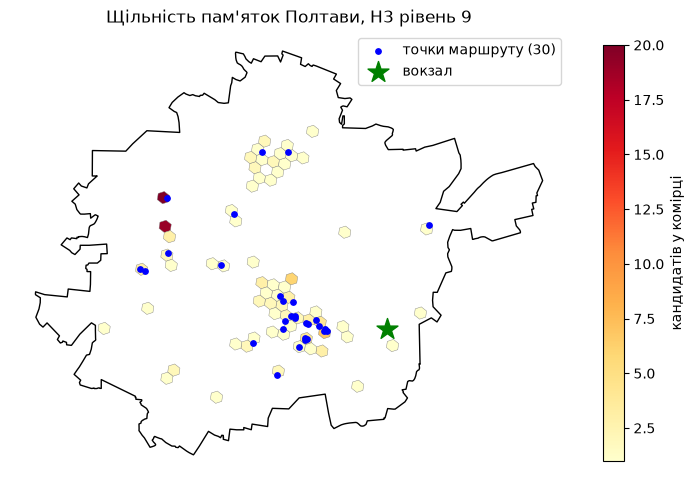

In [30]:
import h3
from shapely.geometry import Polygon

H3_RES = 9
print('середнє ребро комірки: %.0f м' % h3.average_hexagon_edge_length(H3_RES, unit='m'))

# ----- ВАШ КОД -----
# 1) у який шестикутник потрапив кожен кандидат
pts = cand.geometry.representative_point()
cand['h3'] = [h3.latlng_to_cell(p.y, p.x, H3_RES) for p in pts]

# 2) скільки кандидатів у кожному шестикутнику (від найгустішого)
dens = cand['h3'].value_counts()

# 3) перетворюємо шестикутники на полігони для карти
#    cell_to_boundary дає (lat, lng), а shapely чекає (lng, lat) - тому міняємо місцями
hexes = gpd.GeoDataFrame(
    {'h3': dens.index, 'count': dens.values},
    geometry=[Polygon([(lng, lat) for lat, lng in h3.cell_to_boundary(c)]) for c in dens.index],
    crs='EPSG:4326')

# у скількох комірках зосереджено половину кандидатів
half = int((dens.cumsum() < len(cand) / 2).sum()) + 1
print('кандидатів %d, непорожніх комірок %d' % (len(cand), len(dens)))
print('половина кандидатів - у %d комірках з %d' % (half, len(dens)))
print('найгустіші комірки:', dens.head(5).tolist())

# 4) карта
fig, ax = plt.subplots(figsize=(9, 9))
boundary.boundary.plot(ax=ax, color='black', linewidth=1)
hexes.plot(ax=ax, column='count', cmap='YlOrRd', edgecolor='grey', linewidth=0.3,
           legend=True, legend_kwds={'label': 'кандидатів у комірці', 'shrink': 0.6})
pts30.plot(ax=ax, color='blue', markersize=15, label='точки маршруту (30)')
pts30.iloc[[0]].plot(ax=ax, color='green', marker='*', markersize=250, label='вокзал')
ax.set_title("Щільність пам'яток Полтави, H3 рівень 9")
ax.legend()
ax.set_axis_off()
plt.show()

> **Пастка.** `h3.cell_to_boundary` повертає пари **(lat, lng)**, а
> `shapely.Polygon` чекає **(x, y)**, тобто (lng, lat). Переплутаєте - місто
> опиниться в Індійському океані. Це видно одразу, тому дивіться на карту.

### Питання до звіту

У скількох комірках зосереджено половину всіх пам'яток вашого міста?
Що це говорить про форму маршруту?

**Завдання 7.1.** Половина з 146 кандидатів зосереджена в 11 комірках H3 із 67.
Дві найгустіші (20 і 19 об'єктів) - це один музей далекої авіації з експонатами.
Маршрут має щільне ядро в центрі й кілька далеких точок (поле битви, музеї авіації),
тому в ньому є довгі переходи.

---
## 8. Просторове поєднання

### Завдання 8.1

Для кожної точки маршруту знайдіть найближчий заклад із шару `amenities`
(`sjoin_nearest`) і виведіть таблицю з відстанню в метрах.

Нагадування: `sjoin_nearest` рахує в одиницях CRS. У градусах результат буде
безглуздим - перепроєктуйте обидва шари в метричну систему.



In [31]:
# ----- ВАШ КОД -----
# обидва шари - у метри, інакше відстань буде в градусах
pts_m = pts30.to_crs(32635)
am_m = amenities.to_crs(32635)[['amenity', 'name', 'geometry']].rename(columns={'name': 'заклад'})

# до кожної точки маршруту - найближчий заклад і відстань до нього
near = gpd.sjoin_nearest(pts_m, am_m, how='left', distance_col='відстань_м')
near = near[~near.index.duplicated()]          # якщо два заклади на однаковій відстані - лишаємо один
near['відстань_м'] = near['відстань_м'].round().astype(int)

display(near[['name', 'amenity', 'заклад', 'відстань_м']])
print('медіана %d м, максимум %d м, ближче 200 м: %d точок з %d'
      % (near['відстань_м'].median(), near['відстань_м'].max(),
         (near['відстань_м'] <= 200).sum(), len(near)))

,name,amenity,заклад,відстань_м
0,СТАРТ: Вокзал Полтава-Південна,toilets,NaN,69
1,Музей В. Короленка,drinking_water,NaN,351
2,Музей-садиба І. П. Котляревського,restaurant,Лілея,60
3,Полтавський краєзнавчий музей імені Василя Кри...,toilets,NaN,91
4,Літературно-меморіальний музей І.П. Котляревсь...,drinking_water,NaN,234
5,Музей авіації та космонавтики,drinking_water,NaN,291
6,Садиба-музей Панаса Мирного,toilets,NaN,40
7,Полтавський художній музей (галерея мистецтв) ...,cafe,NaN,52
8,Музей важкої бомбардувальної авіації,toilets,NaN,90
9,Полтавська битва,cafe,NaN,741


медіана 91 м, максимум 741 м, ближче 200 м: 21 точок з 31


**Завдання 8.1.** Медіанна відстань від точки маршруту до найближчого закладу - 91 м,
21 з 31 точки мають заклад ближче 200 м. Найгірше біля поля Полтавської битви (741 м)
і музею Короленка (351 м). Відстань по прямій; пішки на ~20 % більше.

---
## 9. Маршрут на карті

Лінія маршруту - це **геометрія ребер графа**, а не відрізки між пам'ятками.

### Завдання 9.1

Побудуйте карту, на якій **обидві** лінії: справжній маршрут по ребрах і
прямі відрізки між точками. Різниця має бути видно оком.

In [32]:
node_xy = nodes.set_index('osmid')[['x', 'y']]

def route_coords(tour, ids):
    """Координати маршруту по ребрах графа у форматі (lat, lon) для folium."""
    coords = []
    for a, b in zip(tour[:-1], tour[1:]):
        try:
            path = nx.shortest_path(G, ids[a], ids[b], weight='length')
        except nx.NetworkXNoPath:
            path = [ids[a], ids[b]]
        for nd in path:
            coords.append((float(node_xy.loc[nd, 'y']), float(node_xy.loc[nd, 'x'])))
    return coords

def add_route(fmap, tour, ids, pts, color, label, show=True):
    """Додає на карту маршрут: лінія по вулицях, прямі відрізки і номери точок."""
    fg = folium.FeatureGroup(name=label, show=show)      # окремий шар, який можна вимкнути

    # 1) справжній маршрут по ребрах графа
    folium.PolyLine(route_coords(tour, ids), color=color, weight=4, opacity=0.8,
                    tooltip=label + ': по вулицях').add_to(fg)

    # 2) прямі відрізки між точками (чорний пунктир)
    straight = [(pts.geometry.iloc[i].y, pts.geometry.iloc[i].x) for i in tour]
    folium.PolyLine(straight, color='black', weight=1.5, dash_array='6', opacity=0.7,
                    tooltip=label + ': по прямій').add_to(fg)

    # 3) кружечки з номерами в порядку обходу (0 - вокзал)
    for step, i in enumerate(tour[:-1]):
        p = pts.geometry.iloc[i]
        html = ('<div style="background:%s;color:white;border-radius:50%%;width:22px;height:22px;'
                'text-align:center;font:bold 12px/22px sans-serif">%d</div>' % (color, step))
        folium.Marker([p.y, p.x], icon=folium.DivIcon(html=html),
                      tooltip='%d. %s' % (step, pts['name'].iloc[i])).add_to(fg)
    fg.add_to(fmap)


center = [pts10.geometry.y.mean(), pts10.geometry.x.mean()]
fmap = folium.Map(location=center, zoom_start=13, tiles=BASEMAP)
add_route(fmap, ex10, ids10, pts10, 'red',  "Оптимальний маршрут, 10 пам'яток")
add_route(fmap, op30, ids30, pts30, 'blue', "2-opt, 30 пам'яток", show=False)
folium.LayerControl(collapsed=False).add_to(fmap)      # перемикач шарів у кутку
fmap.save('lr5_маршрут.html')

print("10 пам'яток: по вулицях %.1f км, по прямій %.1f км"
      % (tour_length(D10, ex10) / 1000, tour_length(E10, ex10) / 1000))
fmap

10 пам'яток: по вулицях 28.2 км, по прямій 21.7 км


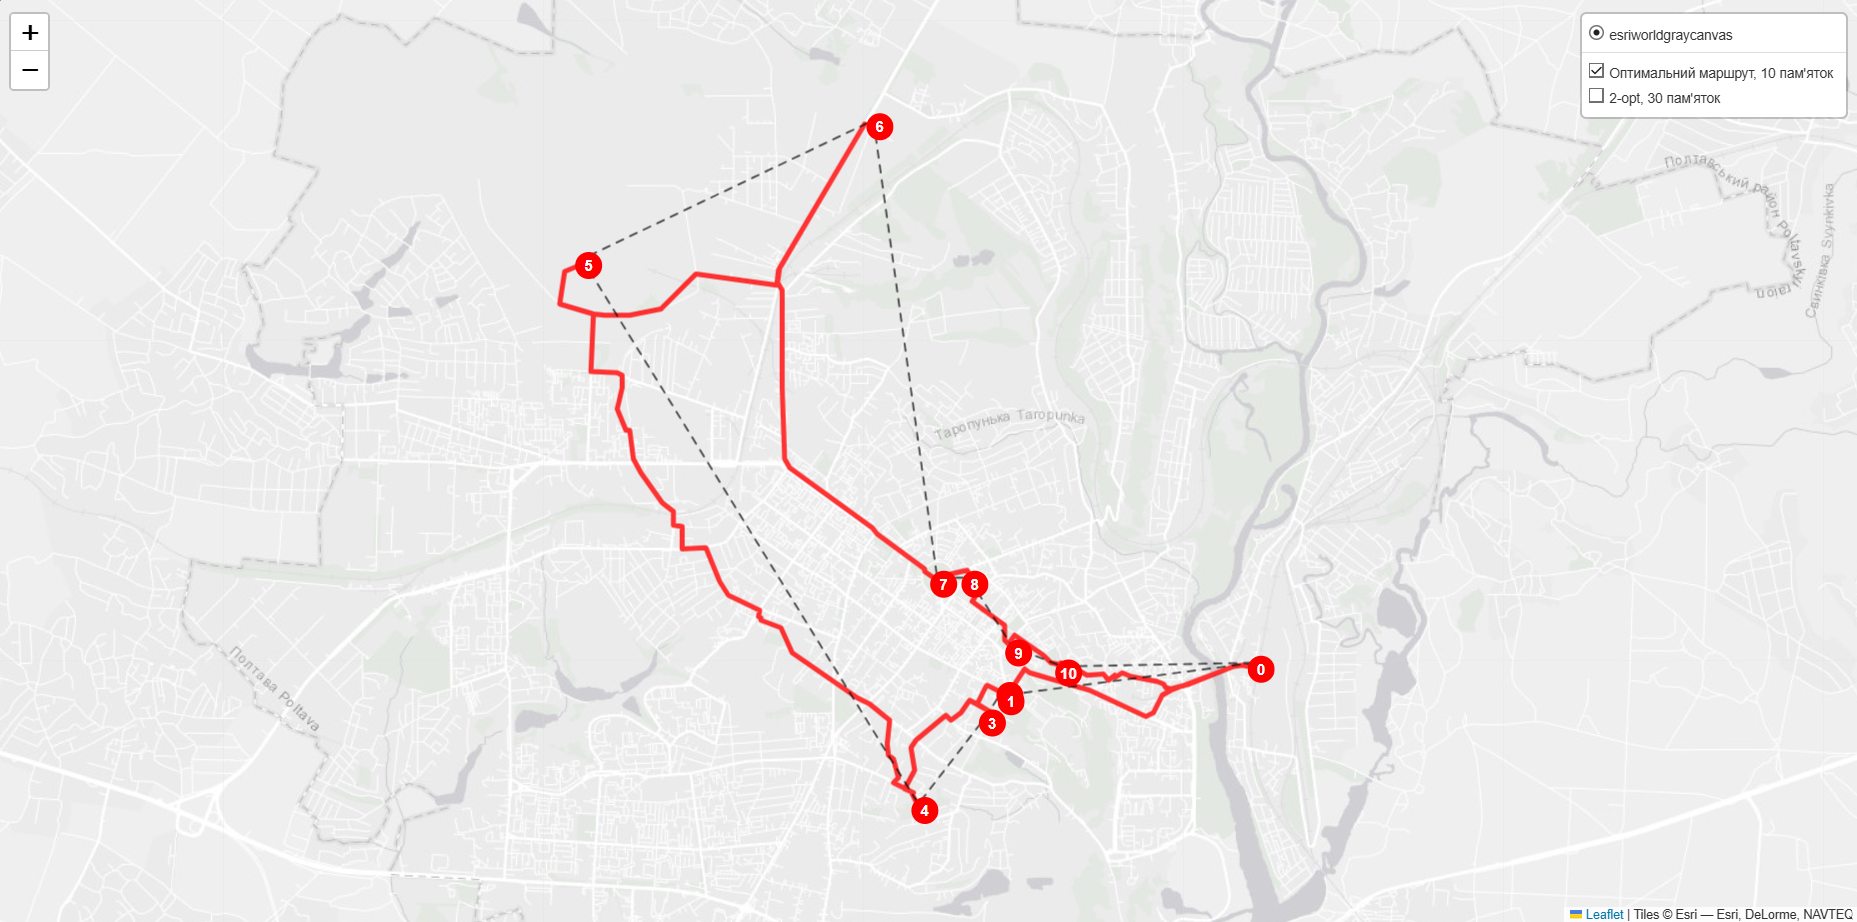

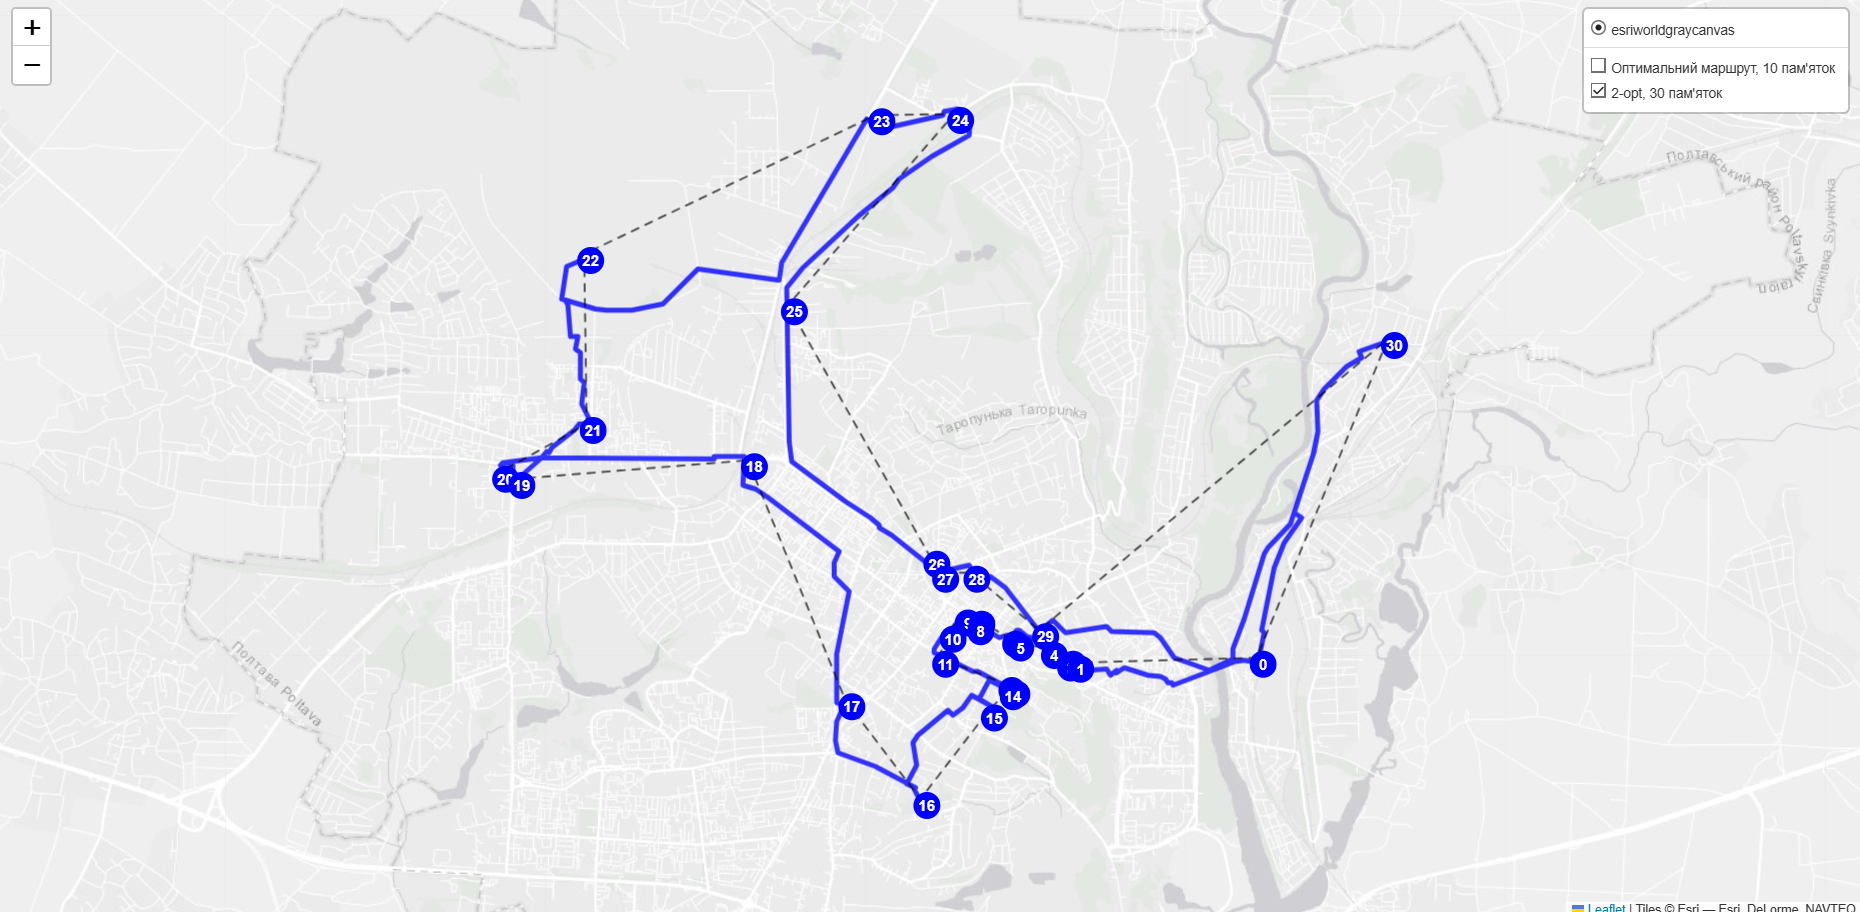

**Завдання 9.1.** Червона лінія - маршрут по ребрах графа (28.2 км), чорний пунктир -
прямі відрізки між тими самими точками (21.7 км). Пішки на 30 % довше, ніж по прямій:
лінія обходить квартали, а найбільше петляє на довгих переходах до поля битви й музеїв авіації.

---
## 10. Результати для лабораторної роботи № 8

Збережіть файл, який ЛР8 прочитає і спробує побити.

In [33]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'місто': CITY,
    'мала_задача': {
        'точок': len(ids10),
        'оптимум_м': round(L_opt, 1),
        'оптимальний_порядок': [str(pts10['name'].iloc[i]) for i in ex10],
        'найближчий_сусід_м': round(tour_length(D10, nn10), 1),
        'двоопт_м': round(tour_length(D10, op10), 1),
    },
    'велика_задача': {
        'точок': len(ids30),
        'найближчий_сусід_м': round(L_nn30, 1),
        'двоопт_м': round(L_op30, 1),
        'двоопт_с': round(t_op30, 4),
        'точки': [{'name': str(pts30['name'].iloc[i]),
                   'lat': float(pts30.geometry.y.iloc[i]),
                   'lon': float(pts30.geometry.x.iloc[i])} for i in range(len(pts30))],
        'матриця_віддалей_м': [[None if not np.isfinite(v) else round(float(v), 1)
                                for v in row] for row in D30],
    },
}
with open('lr5_результати.json', 'w', encoding='utf-8') as f:
    json.dump(result, f, ensure_ascii=False, indent=1)
print('збережено lr5_результати.json (%.1f КБ)' % (os.path.getsize('lr5_результати.json') / 1024))

збережено lr5_результати.json (17.6 КБ)


---
## 11. Звіт

Відповіді пишіть просто в наступній комірці, числами зі своїх обчислень.

1. **Скільки об'єктів ви відкинули** на кроці 2 і за яким правилом? Чи погодились
   би ви віддати цей фільтр замовнику без пояснень?
2. **Які сигнали ввійшли у ваш рейтинг і з якими вагами?** Чому саме так?
3. **Скільки об'єктів збіглося** у ваших двох рейтингах із десяти? Що це
   означає для слова «найкращі»?
4. **Який у вас коефіцієнт обходу** і чи типовий він? Якщо ні - що в місті
   його пояснює?
5. **На скільки відсотків** найближчий сусід гірший за точний розв'язок?
   Чи здивувало вас це число?
6. **Чому точний розв'язок на 30 точках недоступний?** Назвіть конкретну
   величину, яка цьому заважає.
7. **Що у ваших даних виявилось неправильним** - дублікати, пропущені назви,
   об'єкти не на місці? Як ви з цим вчинили?



### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-помічником, у яких саме місцях і як перевіряли
отриманий код. Використання дозволене; **неперевірене** використання - ні.

In [35]:
REPORT = '''
Варіант 17: Полтава. Дані взято живим запитом до Overpass (резервний знімок не використовувався).

1. Відкинуто 32 об'єкти з 183. За тегами (historic=* або tourism з переліку) підійшли всі 183,
   бо ці самі теги вже були в запиті. Відкинуто лише об'єкти без назви: 15 оглядових точок,
   13 меморіалів і по одному хресту, монументу, арт-об'єкту та руїнам. Без пояснень замовнику
   не віддав би: безіменні руїни чи монумент можуть бути справжніми пам'ятками.

2. Чотири сигнали: wiki (0.4), кількість мов назви (0.3), музей/галерея (0.2), площа (0.1).
   Порядок ваг - від найсильнішого сигналу до найслабшого: стаття у Вікіпедії - це визнання
   сторонніх людей, переклади назви - теж, але слабше, музей - місце, куди можна зайти,
   площа - найслабше (великим буває і склад). Мови й площу зведено до рангів 0..1,
   бо їхні шкали дуже різні (площа від 0 до 1.28 км²).

3. Збіглося 7 з 10. Збіг частково випадковий: площа є лише у 21 полігона, і це здебільшого музеї.
   Рейтинг за площею не бачить жодного пам'ятника (площа 0) і ставить першим поле битви просто
   тому, що воно велике. Отже, "найкращі" - це не факт із даних, а наслідок обраного критерію.

4. Коефіцієнт обходу 1.23 (10 точок) і 1.19 (30 точок). Це типово (норма 1.2-1.6):
   у центрі Полтави досить пряма сітка вулиць. Асиметрія 0 м, недосяжних пар немає.

5. Найближчий сусід гірший за точний розв'язок на 5.15 % (29.7 км проти 28.2 км).
   Здивувало, що 2-opt знайшов точний оптимум (той самий маршрут у зворотний бік).
   На 30 точках 2-opt скоротив маршрут найближчого сусіда на 8.9 % (46.5 -> 42.4 км) за 0.001 с.

6. Заважає пам'ять. Таблиця Held-Karp має 2^(n-1)·(n-1) клітин: для 31 точки це
   ~32 млрд клітин, тобто ~258 ГБ лише на одну таблицю (а в коді їх дві: dp і par).
   Це в десятки разів більше за оперативну пам'ять звичайного комп'ютера.

7. Проблеми в даних:
   - дублікати: садиба і хата Котляревського (2 м, однаковий wikidata), літературно-меморіальний
     музей і "Музей Котляревського" (6.6 м) - лишив по одному;
   - 4 гармати ЗіС-3 з однаковим wikidata (він вказує на модель гармати, а не на експонат) - лишив одну;
   - 48 кандидатів (третина) - експонати музею авіації (літаки, гармати, техніка), а не окремі пам'ятки;
   - 32 об'єкти без назви - відкинув;
   - у багатьох кафе й туалетів немає назви;
   - точка поля Полтавської битви стоїть посеред полігона, за 95 м від найближчої доріжки.
   Також сервер Overpass кілька разів повертав 502 (перевантажений), тому для heritage і stations
   обсяг переданих даних узято з файлів кешу.

Висновок, якого не було в завданні: "10 найкращих" за рейтингом не є хорошою пішою прогулянкою.
Маршрут виходить 28 км, бо рейтинг не враховує відстань: поле битви й музеї авіації далеко від центру.
Для туристичного застосунку критерій має враховувати і цінність, і компактність маршруту.

Декларація про використання ШІ:
Користувався ШІ-помічником (Claude) для пояснення завдань і як підказку з кодом у функціях fetch,
відборі кандидатів, рейтингу, check_snap, матрицях, nearest_neighbour, two_opt, H3, sjoin_nearest
і карті. Код запускав сам і перевіряв: вбудовані самоперевірки ноутбука (check_tour, 2-opt не
гірший за вхідний маршрут, Held-Karp не гірший за 2-opt) пройдено, контрольні ознаки збігаються
(різних вузлів стільки ж, скільки точок; коефіцієнт обходу в нормі 1.2-1.6; повторний запуск
дає "знімок" і 0 МБ), карту H3 і маршрут перевірив візуально.
'''
print(REPORT)


Варіант 17: Полтава. Дані взято живим запитом до Overpass (резервний знімок не використовувався).

1. Відкинуто 32 об'єкти з 183. За тегами (historic=* або tourism з переліку) підійшли всі 183,
   бо ці самі теги вже були в запиті. Відкинуто лише об'єкти без назви: 15 оглядових точок,
   13 меморіалів і по одному хресту, монументу, арт-об'єкту та руїнам. Без пояснень замовнику
   не віддав би: безіменні руїни чи монумент можуть бути справжніми пам'ятками.

2. Чотири сигнали: wiki (0.4), кількість мов назви (0.3), музей/галерея (0.2), площа (0.1).
   Порядок ваг - від найсильнішого сигналу до найслабшого: стаття у Вікіпедії - це визнання
   сторонніх людей, переклади назви - теж, але слабше, музей - місце, куди можна зайти,
   площа - найслабше (великим буває і склад). Мови й площу зведено до рангів 0..1,
   бо їхні шкали дуже різні (площа від 0 до 1.28 км²).

3. Збіглося 7 з 10. Збіг частково випадковий: площа є лише у 21 полігона, і це здебільшого музеї.
   Рейтинг за площею не бачит